# Project : Online Shoppers Purchasing Intention

## 1. Introduction

### 1.1 Motivation

Understanding online customer behavior is an important challenge for e-commerce platforms. Predicting whether a visitor will make a purchase can help businesses understand shopping behavior and improve their online experience.

### 1.2 Objective

Predict whether an online shopping session will result in a purchase using the Online Shoppers Purchasing Intention dataset.

### 1.3 Worflow 

1) Exploring and preprocessing dataset
2) Train a classification model
3) Evaluate and compare model performance
4) Interpret the results

In [18]:
# [NOTE] Alexander: ideally we'll have some time on Wednesday to go over the notebook and make it pretty and all.
# For instance, we can talk about how this is supervised learning.
# I added some notes to the code for my own benefit; the final version of the notebook can have some refined version of these comments

## 2. Imports and Dataset load

### 2.1 Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

### 2.2 Load the CSV

In [3]:
# read csv into pandas df
df = pd.read_csv("data/online_shoppers_intention.csv")

# printing to see if it looks alright
print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

None

### 2.3 Structure of the dataset

In [19]:
# what we can expect to see from the variables
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


## 3. Data quality

### 3.1 Missing and duplicate values

In [21]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
# pd.df.isna detects missing values ("is NaN")
# for each column, count missing entries and sort the counts
display(df.isna().sum().sort_values(ascending=False))
# btw, no missing values but 125 duplicate rows? I assume it's alright

Duplicate rows: 125

Missing values per column:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

### 3.2 Inspect target 

In [24]:
print("Revenue values:")
display(df["Revenue"].value_counts(dropna=False))
# so we have a binary classification task with a True or False value. 
# Since the count says there are no Nas, and dropna=False is set, it likely means that all our ys are in order.
# Note the imbalance. A base model that always guesses "False" is right 84.5% of the time.

print("\nData types:")
display(df.dtypes.to_frame(name="Data type"))
# display data types, simple enough

Revenue values:


Revenue
False    10422
True      1908
Name: count, dtype: int64


Data types:


,Data type
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## 4. Data analysis

### 4.1 Distribution of purchase outcomes

Revenue
False    10422
True      1908
Name: Count, dtype: int64

Revenue
False    84.53
True     15.47
Name: Percentage, dtype: float64

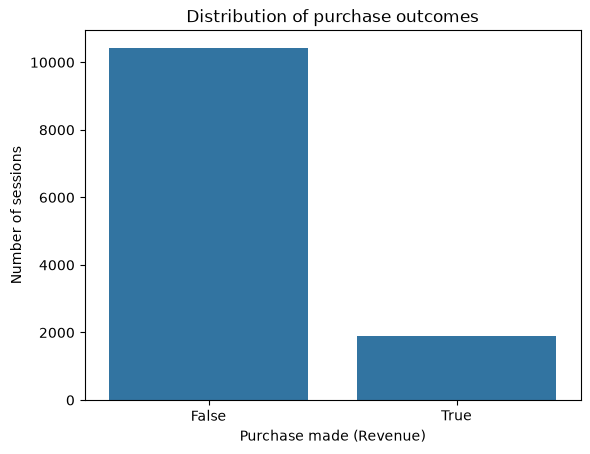

In [25]:
display(df["Revenue"].value_counts().rename("Count"))
display((df["Revenue"].value_counts(normalize=True) * 100).rename("Percentage").round(2))

sns.countplot(data=df, x="Revenue")
# will probably need to make this a bit more colourful in the final submission; I can take care of this later
plt.title("Distribution of purchase outcomes")
plt.xlabel("Purchase made (Revenue)")
plt.ylabel("Number of sessions")
plt.show()

### 4.2 Explore sessions by visitors and months

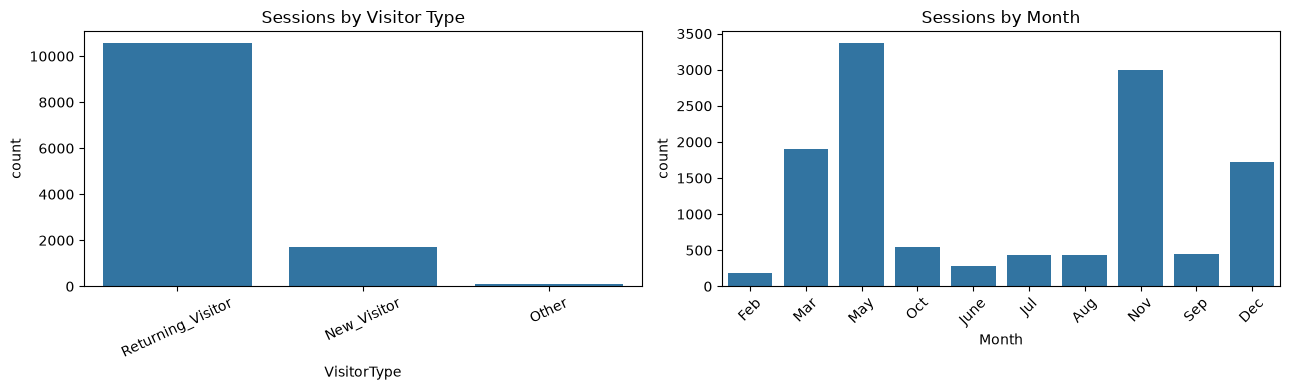

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x="VisitorType", ax=axes[0])
axes[0].set_title("Sessions by Visitor Type")
axes[0].tick_params(axis="x", rotation=25)

sns.countplot(data=df, x="Month", ax=axes[1])
axes[1].set_title("Sessions by Month")
axes[1].tick_params(axis="x", rotation=45)
# The order of the months as displayed here is questionable

plt.tight_layout()
plt.show()

### 4.3 Purchase rate by category (visitor/month)

In [29]:
visitor_rates = df.groupby("VisitorType")["Revenue"].mean().sort_values(ascending=False)
month_rates = df.groupby("Month")["Revenue"].mean().sort_values(ascending=False)
# What does "Other" mean in terms of the dataset? It seems like there are quite few "Others"; the prof will probably ask us what this is
# my personal assistant (Claude? idk what AI model Perplexity gave this task to) says that splitting it into several lines would make it more readable
#month_rates = (
#    df.groupby("Month")["Revenue"]
#    .mean()
#    .sort_values(ascending=False)
#)

# probably needs more explicit comments on what the below code does. 
# I'm pretty trash at this, but if I have questions, the teachers will likely have them too
display(visitor_rates.rename("Purchase rate").to_frame())
display(month_rates.rename("Purchase rate").to_frame())

,Purchase rate
VisitorType,
New_Visitor,0.249115
Other,0.188235
Returning_Visitor,0.139323


,Purchase rate
Month,
Nov,0.253502
Oct,0.209472
Sep,0.191964
Aug,0.175520
Jul,0.152778
Dec,0.125072
May,0.108502
June,0.100694
Mar,0.100682


### 4.4 Selection of features for the visualisation

In [30]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
# same as above - several lines? we should work out a visual style we'll agree on

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


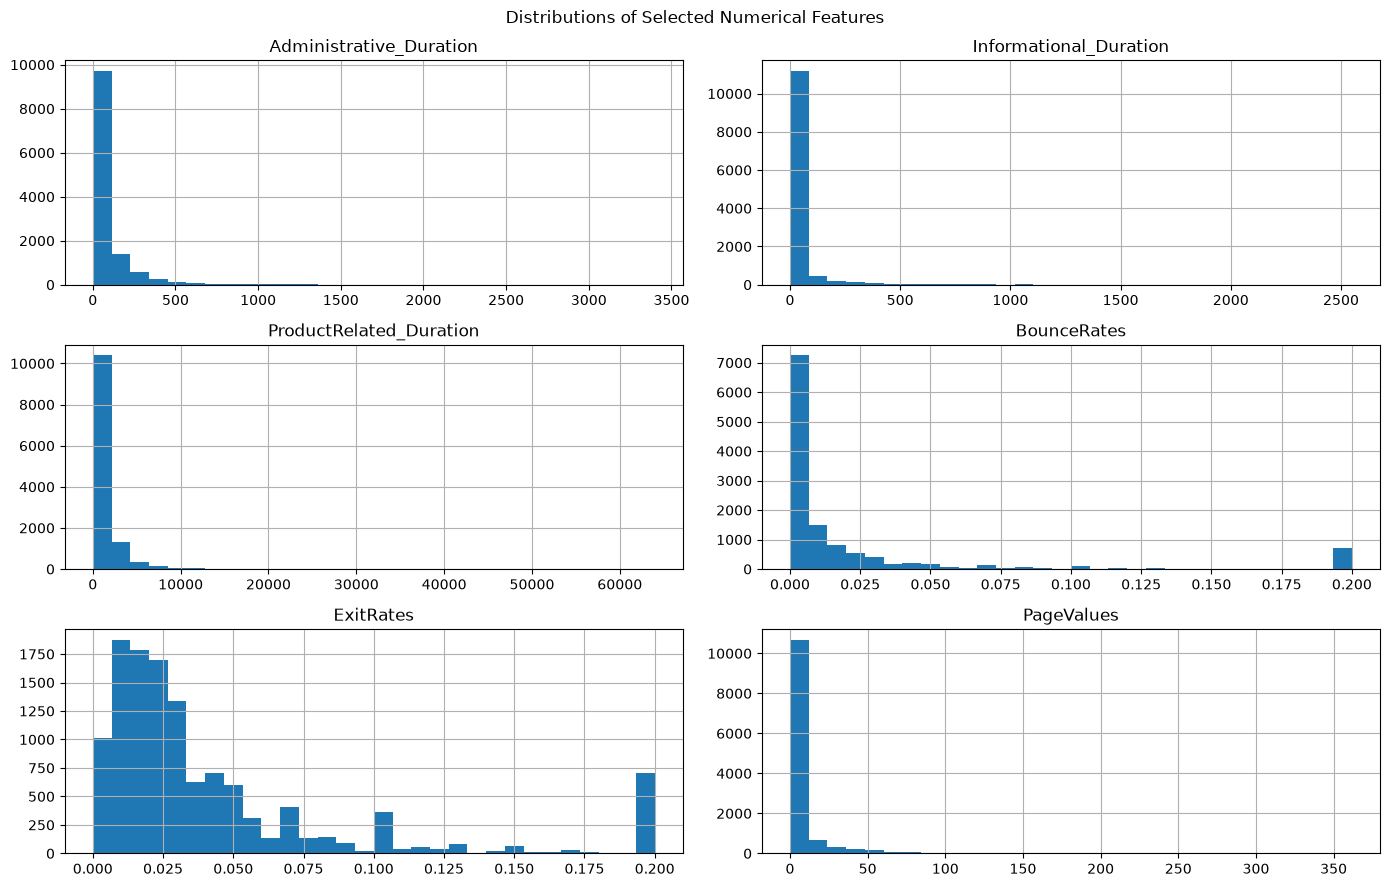

In [11]:
features_to_plot = ["Administrative_Duration","Informational_Duration","ProductRelated_Duration","BounceRates","ExitRates","PageValues"]

df[features_to_plot].hist(figsize=(14, 9), bins=30)
plt.suptitle("Distributions of Selected Numerical Features")
plt.tight_layout()
plt.show()

### 4.5 Comparing avg feature values by revenue

In [31]:
comparison_features = ["PageValues","ProductRelated_Duration","ProductRelated","BounceRates","ExitRates"]

display(df.groupby("Revenue")[comparison_features].mean().T.rename(columns={False: "No purchase", True: "Purchase"}))
# same as above

Revenue,No purchase,Purchase
PageValues,1.975998,27.264518
ProductRelated_Duration,1069.987809,1876.209615
ProductRelated,28.714642,48.210168
BounceRates,0.025317,0.005117
ExitRates,0.047378,0.019555


## 5. Feature preparation

### 5.1 Defining x and y

In [13]:
target = "Revenue"

# input table: all columns except the answer
X = df.drop(columns=[target])
# correct answers: False/True as 1/0
y = df[target].astype(int)

print("Features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

Features: 17
Target classes: [np.int64(0), np.int64(1)]


### 5.2 Defining feature types

In [32]:
categorical_cols = X.select_dtypes(include=["object", "category", "bool", "str", "string"]).columns.tolist()
# separates columns according to their storage type
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# checks that two lists account together for all input columns
assert len(categorical_cols) + len(numerical_cols) == X.shape[1]

Categorical columns: ['Month', 'VisitorType', 'Weekend']
Numerical columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


### 5.3 Train/Test split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# we do be train-test splitting 💯💯💯

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training purchase rate:", round(y_train.mean(), 4))
print("Test purchase rate:", round(y_test.mean(), 4))

Training set: (9864, 17)
Test set: (2466, 17)
Training purchase rate: 0.1547
Test purchase rate: 0.1549


### 5.4 Preprocessing

In [34]:
# imputation replaces missing values. 
# median - uses learned medians
# standard-scales - calculates z score (z := (x - mu_train) / sigma_train)
# a comment on the central limit theorem, mayhaps? about how the sample size is large enough for us to assume that the sample std. dev. is the population std. dev.
# idk, I don't insist
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

# learns most frequent category and imputes
# OneHotEncored converts a categorical feature into indocator columns
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([("numeric", numeric_pipeline, numerical_cols),("categorical", categorical_pipeline, categorical_cols)])

In [35]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

### 6. à vous !

### 6. Learning

In [37]:
# dummy model that always guesses the most frequent class
from sklearn.dummy import DummyClassifier

# fix seed for reproducible results
SEED = 42

# create classifier
dummy_model = DummyClassifier(strategy="prior")

# fit classifier. Unlike a real one, this one ignores feature values.
dummy_model.fit(X_train, y_train)

# show the class labels and their learned proportions
dummy_distribution = pd.Series(
    dummy_model.class_prior_,
    index=dummy_model.classes_,
    name="Training class proportion"
)

display(dummy_distribution)

0    0.845296
1    0.154704
Name: Training class proportion, dtype: float64

In [41]:
# take five training sessions simply to inspect the model's behaviour
# demonstration only
example_sessions = X_train.iloc[:5]
example_predictions = dummy_model.predict(example_sessions)

# create probabilities for each class
example_probabilities = dummy_model.predict_proba(example_sessions)

# one should see the same prediction for every session and the same probability vector for every session.
# huzzah, this is what we see
print("Class order:", dummy_model.classes_)
print("Predicted labels:", example_predictions)
print("Predicted probabilities:")
print(example_probabilities)

Class order: [0 1]
Predicted labels: [0 0 0 0 0]
Predicted probabilities:
[[0.84529603 0.15470397]
 [0.84529603 0.15470397]
 [0.84529603 0.15470397]
 [0.84529603 0.15470397]
 [0.84529603 0.15470397]]


In [45]:
# define the cross-validation folds and metrics
from sklearn.model_selection import StratifiedKFold, cross_validate
# I'm just going off Perplexity atp, if this is way outside the program and you guys know this, lmk
# if these comments end up in the submission, I swear...
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

# Divide the training data into five folds, of which:
# - four are used for fitting;
# - the remaining fold is used for validation
# stratification approximately preserves the 1/0 ratio in every fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# define metrics that will be recorded for every model
# keys are labels
# values specify how each score is calculated
scoring = {
    # what proportion of all predictions are correct?
    # course formula (slide 43/61 of CM 1 (Landscape Overview):
    # (TP + TN) / (TP + TN + FP + FN) = (TP + TN) / all
    "accuracy":"accuracy",
    
    # how good is the precision-recall trade-off across score thresholds?
    "ap":"average_precision",
    
    # how well do its scores rank purchasers above non-purchasers?
    # course: area under the receiver operating characteristic curve, measures discrimination ability
    "roc_auc":"roc_auc",

    # if a model predicts no positive cases, precision is undefined
    # zero_division=0 reports zero instead of going ape-mode
    # what does make_scorer do, exactly?

    # of the predicted purchasers, how many really purchased?
    # course formula:
    # precision = TP / (TP + FP)
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),

    # of the actual purchasers, how many did the model detect?
    # recall = TP / (TP + FN)
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),

    # you guys seen F1 (the movie)? I did, watched it in the cinema, quite liked it
    # how well does the model balance precision and recall at its prediction rule?
    # something something stats tables
    # harmonic mean of precision and recall
    # F1 = 2 * (precision * recall) / (precision + recall)
    "f1": make_scorer(
        f1_score,
        zero_division=0
    )
}

In [53]:
# evaluate dummy model with cross-validation
# establish reference scores
dummy_cv = cross_validate(
    estimator=dummy_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    # record performance on the fitting portion of each fold
    return_train_score=True,
    # run folds in parallel using available cpu cores
    #n_jobs=-1,
    #error_score="raise"
    # left those in in case we need them, but this is clearly AI slop.
)

# summarise the five validation scores for each metric
# what is even the type of this? pandas.df([Dict[str:Dict[i'm lost]]])
# if this stays in the final version, we need the types sorted out in the comments
dummy_summary = pd.DataFrame({
    "mean_validation_score":{
        metric:dummy_cv[f"test_{metric}"].mean()
        for metric in scoring
    },
    "std_across_folds":{
        metric:dummy_cv[f"test_{metric}"].std()
        for metric in scoring
    }
})

display(dummy_summary.round(4))
# recall, precision, f1 should be 0 because it predicts no puchases
# roc should be 0.5 because all sessions receive the same score
# ap approximately equals purchase proportion
# accuracy approximately equals non-purchase proportion
# huzzah, this is true

,mean_validation_score,std_across_folds
accuracy,0.8453,0.0002
ap,0.1547,0.0002
roc_auc,0.5000,0.0000
precision,0.0000,0.0000
recall,0.0000,0.0000
f1,0.0000,0.0000


In [55]:
# actual fitting stuff
# hope this makes sense; the comments we leave on the actual rendu should explain this in detail

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# Each entry contains:
# - an unfitted classifier;
# - a dictionary of hyperparameter values to investigate.
experiments = {
    "Logistic regression": (
        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        ),
        {
            # Smaller C means stronger regularization.
            "model__C": [0.01, 0.1, 1, 10],

            # Compare ordinary fitting with class-weighted fitting.
            "model__class_weight": [None, "balanced"]
        }
    ),

    "Decision tree": (
        DecisionTreeClassifier(
            random_state=SEED
        ),
        {
            # Limit the number of split levels.
            # None allows growth without an explicit depth limit.
            "model__max_depth": [3, 5, 8, None],

            # Larger leaves prevent very specific, small-sample rules.
            "model__min_samples_leaf": [1, 5, 20],

            "model__class_weight": [None, "balanced"]
        }
    ),

    "Random forest": (
        RandomForestClassifier(
            random_state=SEED,

            # Parallelize the search rather than each individual forest.
            n_jobs=1
        ),
        {
            # Number of trees in the forest.
            "model__n_estimators": [200, 400],

            "model__max_depth": [8, 15, None],
            "model__min_samples_leaf": [1, 5, 15],

            # Number/fraction of features considered at each split.
            "model__max_features": ["sqrt", 0.7],

            "model__class_weight": [None, "balanced"]
        }
    ),

    "Gradient boosting": (
        GradientBoostingClassifier(
            random_state=SEED
        ),
        {
            # Number of sequential boosting stages.
            "model__n_estimators": [100, 200],

            # Contribution of each newly added tree.
            "model__learning_rate": [0.03, 0.1],

            # Complexity of each individual tree.
            "model__max_depth": [2, 3],
            "model__min_samples_leaf": [5, 20],

            # Fraction of training examples used at each stage.
            "model__subsample": [0.8, 1.0]
        }
    )
}

In [59]:
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV

# Keep the fitted search object for every model.
# This gives us access to its best pipeline and detailed results later.
searches = {}

# Start the comparison table with the dummy baseline.
# It has no hyperparameter search.
results_rows = [{
    "model": "Dummy",
    "train_AP": dummy_cv["train_ap"].mean(),
    "validation_AP": dummy_cv["test_ap"].mean(),
    "validation_AP_std": dummy_cv["test_ap"].std(),
    "validation_accuracy": dummy_cv["test_accuracy"].mean(),
    "validation_ROC_AUC": dummy_cv["test_roc_auc"].mean(),
    "validation_precision": dummy_cv["test_precision"].mean(),
    "validation_recall": dummy_cv["test_recall"].mean(),
    "validation_F1": dummy_cv["test_f1"].mean(),
    "best_params": {}
}]

for model_name, (classifier, parameter_space) in experiments.items():

    print(f"Training and tuning: {model_name}")

    # clone() copies the configuration without any fitted state.
    # Each model therefore receives its own preprocessing object.
    model_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(classifier))
    ])

    search = RandomizedSearchCV(
        estimator=model_pipeline,
        param_distributions=parameter_space,

        # Evaluate eight candidate configurations per model.
        n_iter=8,

        # Record all previously defined metrics.
        scoring=scoring,

        # Select the best configuration using validation AP,
        # then fit it again on the entire training set.
        refit="ap",

        # Use the same fold-generation settings for every model.
        cv=cv,

        # Reproduce the sampled hyperparameter combinations.
        random_state=SEED,

        # Parallelize candidate/fold fits.
        # same reason as above - ai slop
        #n_jobs=-1,

        # Record training scores to help identify overfitting.
        return_train_score=True,

        # Show errors immediately during development.
        #error_score="raise"
    )

    # This performs cross-validation, selects the best settings,
    # and refits the selected pipeline.
    # X_test and y_test are not involved.
    search.fit(X_train, y_train)

    searches[model_name] = search

    # cv_results_ contains a result row for every tested configuration.
    # best_index_ identifies the configuration selected by validation AP.
    best_index = search.best_index_
    cv_results = search.cv_results_

    results_rows.append({
        "model": model_name,
        "train_AP": cv_results["mean_train_ap"][best_index],
        "validation_AP": cv_results["mean_test_ap"][best_index],
        "validation_AP_std": cv_results["std_test_ap"][best_index],
        "validation_accuracy": cv_results[
            "mean_test_accuracy"
        ][best_index],
        "validation_ROC_AUC": cv_results[
            "mean_test_roc_auc"
        ][best_index],
        "validation_precision": cv_results[
            "mean_test_precision"
        ][best_index],
        "validation_recall": cv_results[
            "mean_test_recall"
        ][best_index],
        "validation_F1": cv_results[
            "mean_test_f1"
        ][best_index],
        "best_params": search.best_params_
    })

Training and tuning: Logistic regression
Training and tuning: Decision tree
Training and tuning: Random forest
Training and tuning: Gradient boosting


In [60]:
# the real-model search in the cell above involves 160 cross-validation fits:
# 4 models * 8 configurations * 5 folds
results_rows

[{'model': 'Dummy',
  'train_AP': np.float64(0.15470397380220352),
  'validation_AP': np.float64(0.15470397012817047),
  'validation_AP_std': np.float64(0.00019724843424045145),
  'validation_accuracy': np.float64(0.8452960298718295),
  'validation_ROC_AUC': np.float64(0.5),
  'validation_precision': np.float64(0.0),
  'validation_recall': np.float64(0.0),
  'validation_F1': np.float64(0.0),
  'best_params': {}},
 {'model': 'Logistic regression',
  'train_AP': np.float64(0.6624207825803486),
  'validation_AP': np.float64(0.6593783969388152),
  'validation_AP_std': np.float64(0.01728130222510732),
  'validation_accuracy': np.float64(0.8612127308934305),
  'validation_ROC_AUC': np.float64(0.9058072366712008),
  'validation_precision': np.float64(0.5365371829459437),
  'validation_recall': np.float64(0.7621086467373834),
  'validation_F1': np.float64(0.6296742609544154),
  'best_params': {'model__class_weight': 'balanced', 'model__C': 1}},
 {'model': 'Decision tree',
  'train_AP': np.floa

In [61]:
# display results
comparison = pd.DataFrame(results_rows)

# Sort models from highest to lowest mean validation AP.
comparison = (
    comparison
    .sort_values("validation_AP", ascending=False)
    .reset_index(drop=True)
)

# A large positive gap can indicate overfitting.
comparison["AP_train_validation_gap"] = (
    comparison["train_AP"] - comparison["validation_AP"]
)

# Show numerical results separately from the parameter dictionaries.
display(
    comparison.drop(columns="best_params").round(4)
)

# Print the chosen settings in a more readable format.
for _, row in comparison.iterrows():
    print(f"\n{row['model']}")
    print(row["best_params"])

,model,train_AP,validation_AP,validation_AP_std,validation_accuracy,validation_ROC_AUC,validation_precision,validation_recall,validation_F1,AP_train_validation_gap
0,Random forest,0.8418,0.7548,0.0153,0.9055,0.9329,0.7377,0.6055,0.6646,0.0870
1,Gradient boosting,0.8015,0.7512,0.0154,0.9040,0.9327,0.7265,0.6101,0.6629,0.0503
2,Decision tree,0.8098,0.6903,0.0250,0.8967,0.9060,0.7070,0.5747,0.6328,0.1195
3,Logistic regression,0.6624,0.6594,0.0173,0.8612,0.9058,0.5365,0.7621,0.6297,0.0030
4,Dummy,0.1547,0.1547,0.0002,0.8453,0.5000,0.0000,0.0000,0.0000,0.0000



Random forest
{'model__n_estimators': 200, 'model__min_samples_leaf': 15, 'model__max_features': 0.7, 'model__max_depth': 8, 'model__class_weight': None}

Gradient boosting
{'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_depth': 3, 'model__learning_rate': 0.03}

Decision tree
{'model__min_samples_leaf': 20, 'model__max_depth': 8, 'model__class_weight': None}

Logistic regression
{'model__class_weight': 'balanced', 'model__C': 1}

Dummy
{}


In [62]:
# Exclude the dummy when choosing among the real classifiers.
real_model_results = comparison[
    comparison["model"] != "Dummy"
]

# The table is already sorted by validation AP.
best_name = real_model_results.iloc[0]["model"]

# RandomizedSearchCV has already fitted this pipeline
# on all of X_train using the selected hyperparameters.
best_pipeline = searches[best_name].best_estimator_

best_ap = searches[best_name].best_score_
dummy_ap = dummy_cv["test_ap"].mean()

print("Selected real model:", best_name)
print("Mean validation AP:", round(best_ap, 4))
print("Dummy validation AP:", round(dummy_ap, 4))
print("Selected hyperparameters:")
print(searches[best_name].best_params_)

if best_ap <= dummy_ap:
    print(
        "Warning: the selected classifier did not outperform "
        "the dummy baseline on mean validation AP."
    )

Selected real model: Random forest
Mean validation AP: 0.7548
Dummy validation AP: 0.1547
Selected hyperparameters:
{'model__n_estimators': 200, 'model__min_samples_leaf': 15, 'model__max_features': 0.7, 'model__max_depth': 8, 'model__class_weight': None}
